# 06 · Artículos: línea y familia de producto

Este notebook añade a cada fase la línea y la familia de producto del artículo que se fabrica, a partir de las tablas
de artículos, líneas y familias del ERP.

- **Entrada:** `STKArticle.csv`, `ProductLine.csv`, `ProductFamily.csv` (en `data/raw/`) y `data/processed/df_FASE_final.parquet`
- **Salida:** `data/processed/df_final.parquet`

In [8]:
import sys
from pathlib import Path

# Raíz del repositorio (la carpeta que contiene src/), para poder importar src
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

import matplotlib.cm as cm
import matplotlib.pyplot as plt
import pandas as pd

from src.columnas import COLUMNAS_ARTICULOS, COLUMNAS_FAMILIAS, COLUMNAS_LINEAS, leer_csv
from src.limpieza import eliminar_columnas
from src.rutas import FIGURES, PROCESSED

pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)

## 1. Artículos del ERP

Solo se trabaja con los artículos de la planta 100 (`CodCompany = 100`) y se prescinde de los atributos que no se
usan.

In [9]:
df_article = leer_csv("STKArticle.csv", COLUMNAS_ARTICULOS)
df_article = df_article[df_article["CodCompany"] == 100]
print(df_article.shape)

(50312, 98)


In [10]:
COLUMNAS_SOBRAN = [
    "CodCompany", "Notes", "Image", "LocationWarehouseControl", "SeriesControl",
    "UnitarianSeries", "ExpiryControl", "ExpireDays", "IDUnitQuantityWarehouse",
    "IDUnitPriceWarehouse", "SecondUnit", "IDUnitSecondUnit", "IDUnitQuantityPurchase",
    "IDUnitPricePurchase", "IDProductSubFamily", "StatisticsCode", "CodCountryOfOrigin",
    "SupplemetUnit", "IDUnitSupplement", "AverageSecondUnit", "Dimension",
    "ApplyPurchaseDiscount", "ApplyPurFinancialSurcharge", "IDAttribute1", "IDAttribute2",
    "IDAttribute3", "IDAttributeValue1", "IDAttributeValue2", "IDAttributeValue3",
    "IDArticleGeneric", "CodArticlePrevious", "IDUnitHomogeneousPurchase", "PlanningCategory",
    "PlanningGroup", "NetWeight", "MakeAutomaticOutput", "ImputationCostUpdated",
    "InvestmentExpense", "IDUnitQuantitySales", "IDUnitPriceSales", "ApplySalesDiscount",
    "ApplySalesFinancialSurcharge", "IDUnitHomogeneousSales", "AverageSecondUnitSerie",
    "GrossWeight", "Container", "HasContainer", "DiscountContainer", "IDStatusLotGroup",
    "StatusLot", "ConsumePrevisionBehavior", "PDMItemID", "ImputationTotalQuantity",
    "GroupDaysNumber", "TechnicalDescription", "MRPPrevisionsOnly", "ApplySalesRetention",
    "ApplyPurchaseRetention", "RowTimestamp", "LastModifiedBy", "QuantityBaseFormula",
    "IDUnitBaseFormula", "PotencyControl", "PotencyDefault", "BatchBalancing",
    "MultipleCADLink", "ComponentsGroupType", "InactiveDate", "WholeSeries", "LotsReserve",
    "LotsReserveDays", "LotsOrder", "LotsOrderDays", "SecondUnitFixed", "MatchCode",
    "UnitarianSerieOrder", "IDArticleContainer", "CreationTimestamp", "RowCreatedBy",
    "ApplyCommission", "ApplySalesDiscountPP", "ApplyPurchaseDiscountPP",
    "IDArticleClassification", "ManufacturingGroupCode", "ManufacturingGroupQuantity",
    "MaterialPreparationType", "NotBillablePurchase", "NotBillableSales",
    "NotApplyNetWeightNetMass", "UDI", "UDIBasic", "HSCode", "GroupDays",
]

df_article = eliminar_columnas(df_article, COLUMNAS_SOBRAN)
df_article = df_article.rename(columns={
    "CodArticle": "Código Artículo",
    "Description": "Descripción Artículo",
    "IDProductLine": "ID Línea de Producto",
    "IDProductFamily": "ID Família de Producto",
})
df_article.head(3)

Eliminadas 93 columnas. Quedan 5 columnas y 50312 filas.


,IDArticle,Código Artículo,Descripción Artículo,ID Línea de Producto,ID Família de Producto
0,0000135a-caf7-4291-a30b-9928c6bccca2,103109632,Tête PE,NaN,NaN
1,000221a1-6a29-4915-ab6f-814a0e633e86,ITCXA3X0003,Schraubkonuns für Elektroenschaft Ø16 (5869123),f12d453c-c42d-4fe6-9684-dda95daf8680,3bfeae7e-fec0-4d75-9bec-f48cdd922ef2
2,00032a7a-eddc-41e0-8050-6f78bc6b68e1,097625004027,CENTRADOR_TUERCA_M6,4ecefb5d-f4fd-409e-b331-5e4b1964290c,450b6042-5939-427c-8249-44248075d922


## 2. Nombres de la línea y de la familia de producto

Los artículos solo guardan el identificador de su línea y de su familia. Se añaden su código y su nombre.

In [11]:
df_line = leer_csv("ProductLine.csv", COLUMNAS_LINEAS)
df_family = leer_csv("ProductFamily.csv", COLUMNAS_FAMILIAS)
print(f"Líneas de producto: {len(df_line)} | familias de producto: {len(df_family)}")

df_article = df_article.merge(
    df_line[["IDProductLine", "CodProductLine", "Description"]].rename(columns={"Description": "Nombre Línea"}),
    left_on="ID Línea de Producto", right_on="IDProductLine", how="left")

df_article = df_article.merge(
    df_family[["IDProductFamily", "CodProductFamily", "Description"]].rename(columns={"Description": "Nombre Família"}),
    left_on="ID Família de Producto", right_on="IDProductFamily", how="left")

df_article = df_article.drop(columns=["IDArticle", "ID Línea de Producto", "ID Família de Producto",
                                      "IDProductLine", "IDProductFamily"])

print(f"Líneas de producto con artículos: {df_article['CodProductLine'].nunique()}")
print(f"Familias de producto con artículos: {df_article['CodProductFamily'].nunique()}")
print(f"Artículos sin línea de producto: {df_article['CodProductLine'].isna().sum()}")
df_article.head(3)

Líneas de producto: 18 | familias de producto: 82
Líneas de producto con artículos: 18
Familias de producto con artículos: 76
Artículos sin línea de producto: 25595


,Código Artículo,Descripción Artículo,CodProductLine,Nombre Línea,CodProductFamily,Nombre Família
0,103109632,Tête PE,NaN,NaN,NaN,NaN
1,ITCXA3X0003,Schraubkonuns für Elektroenschaft Ø16 (5869123),IT,Nivells Inferiors Torns,ITC,Con Postís
2,097625004027,CENTRADOR_TUERCA_M6,T,Varis Torn,TCN,Centrador


## 3. Unión con las fases

Cada fase se une con su artículo a través del código del material (`smMaterialId`).

In [12]:
df_FASE_final = pd.read_parquet(PROCESSED / "df_FASE_final.parquet")

df_final = df_FASE_final.merge(df_article, left_on="smMaterialId", right_on="Código Artículo", how="left")
print(f"Fases antes: {len(df_FASE_final)} | después de la unión: {len(df_final)} (deben coincidir)")
print(f"Columnas: {df_final.shape[1]}\n")

print(f"Líneas de producto distintas: {df_final['CodProductLine'].nunique()}")
print(f"Familias de producto distintas: {df_final['CodProductFamily'].nunique()}")
print(f"Fases sin línea de producto: {df_final['CodProductLine'].isna().sum()}")

Fases antes: 14689 | después de la unión: 14689 (deben coincidir)
Columnas: 39

Líneas de producto distintas: 17
Familias de producto distintas: 44
Fases sin línea de producto: 95


## 4. Distribución de las fases por línea y familia de producto

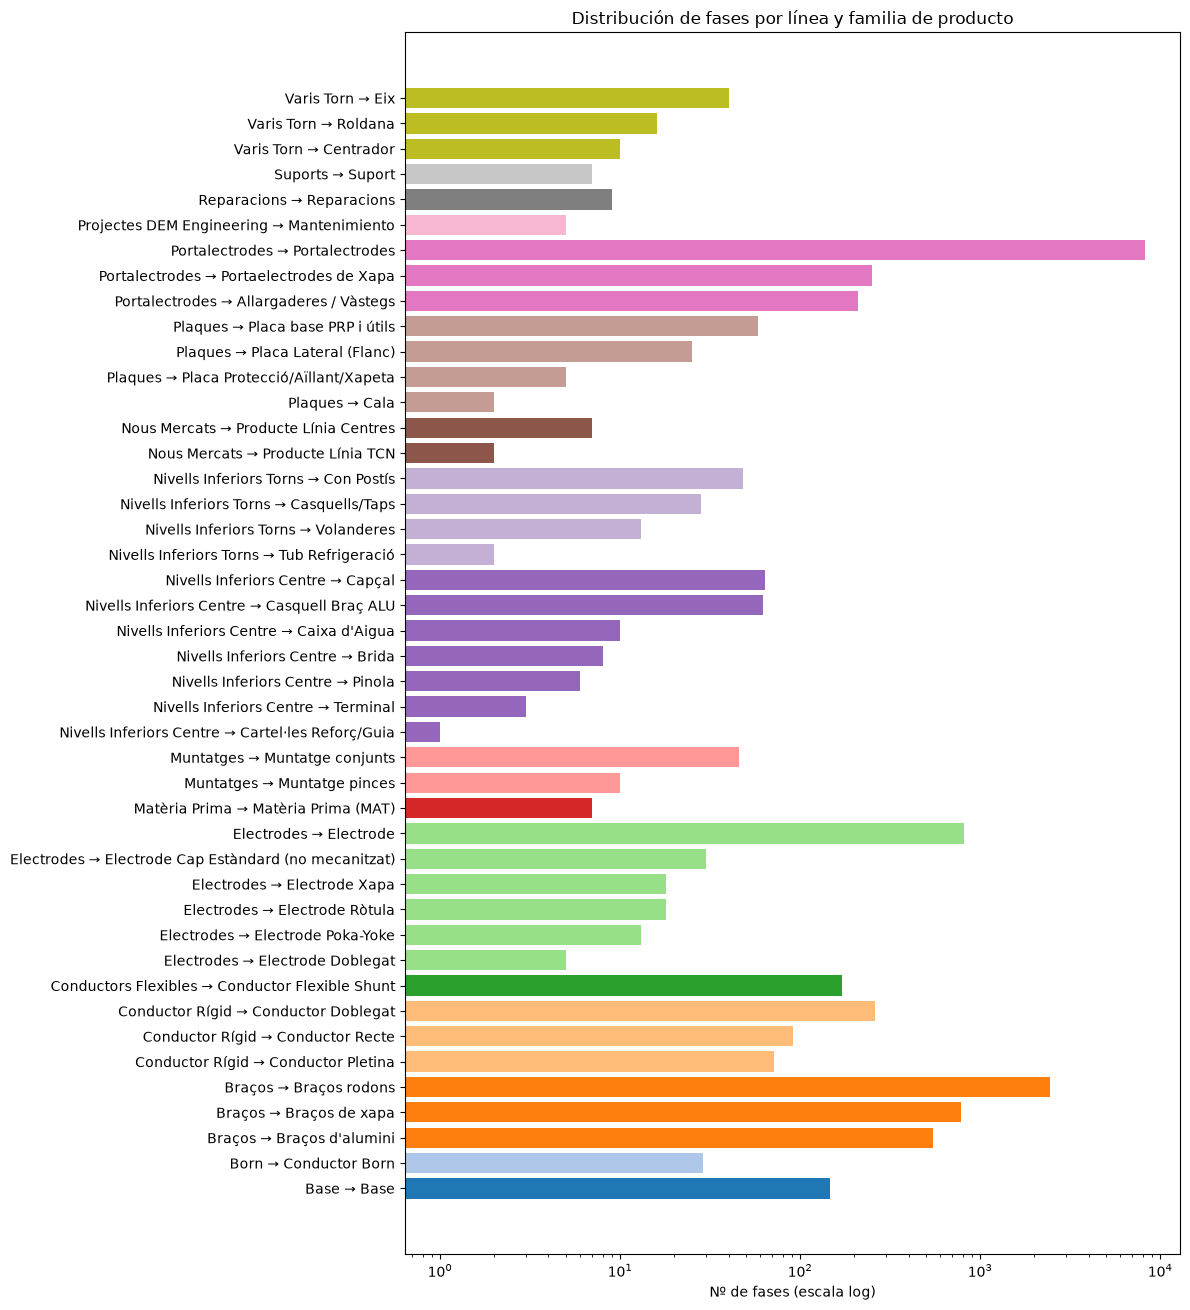

In [13]:
conteo = df_final.groupby(["Nombre Línea", "Nombre Família"]).size().reset_index(name="conteo")
conteo = conteo.sort_values(["Nombre Línea", "conteo"], ascending=[True, True])
conteo["etiqueta"] = conteo["Nombre Línea"] + " → " + conteo["Nombre Família"]  # jerarquía línea → familia

lineas_unicas = conteo["Nombre Línea"].unique()
color_map = dict(zip(lineas_unicas, cm.tab20(range(len(lineas_unicas)))))

fig, ax = plt.subplots(figsize=(12, len(conteo) * 0.3))
ax.barh(conteo["etiqueta"], conteo["conteo"], color=conteo["Nombre Línea"].map(color_map))
ax.set_xscale("log")
ax.set_xlabel("Nº de fases (escala log)")
plt.title("Distribución de fases por línea y familia de producto")
plt.tight_layout()
plt.savefig(FIGURES / "06_fases_por_linea_y_familia.png", dpi=200, bbox_inches="tight")
plt.show()

## 5. Guardado

In [14]:
df_final.to_parquet(PROCESSED / "df_final.parquet")

## Resumen

El dataset tiene 14.689 fases, cada una con su máquina, su familia de máquina, sus tiempos teórico y real, y la
línea y la familia de producto del artículo. 95 fases no tienen línea de producto asignada.